# Lab 02 · NumPy for Numerical Computing
CS-3105 Machine Learning Lab · Lab Instructor: Engr. Muhammad Awais

CLO 5 (C-3 Apply, PLO 5 Modern Tool Usage): *Use Python programming and tools to perform data handling and basic operations.*

**Rules:** no Python loops where a NumPy function exists · label every output, e.g. `print("T6b:", ...)` · Runtime → Restart and run all before you submit · push to `ML-Lab-2024-SE-36/Lab02/Lab02.ipynb` by Thursday 29 Oct, 11:59 PM.

Name: Sahadat Ali  Roll No:2024-SE-36.

### Datasets (run this cell first, do not edit)
- **Census 2023**: Pakistan Bureau of Statistics, 7th Population and Housing Census (provinces, ICT, AJK, GB).
- **Climate**: 1991–2020 climate normals (PMD / WMO) as published in the city climate tables.
- **Inflation**: Pakistan Economic Survey 2024-25, Chapter 7, Fig 7.1 (PBS CPI, year-on-year %).
- **Marks**: sample lab-section marks.

In [12]:
import numpy as np

# ===================== DATASETS (given to students in the starter notebook) =====================
# D1. Population Census 2023 (PBS), source: 2023 Pakistani census results
units = np.array(["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Islamabad", "AJK", "Gilgit-Baltistan"])
pop_2023 = np.array([127_688_922, 55_696_147, 40_856_097, 14_894_402, 2_363_863, 4_333_467, 1_709_049])
pop_2017 = np.array([109_989_655, 47_854_510, 35_501_964, 12_335_129, 2_003_368, 4_045_367, 1_492_924])

# D2. Climate normals 1991-2020 (PMD / WMO), mean daily maximum temperature (°C) and rainfall (mm)
cities = np.array(["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"])
months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
tmax = np.array([
    [18.4, 22.2, 27.5, 34.2, 38.9, 38.9, 35.6, 34.7, 34.4, 32.4, 27.1, 21.4],   # Lahore
    [26.3, 28.7, 32.6, 35.0, 35.7, 35.7, 33.6, 32.5, 33.4, 35.6, 32.6, 28.4],   # Karachi
    [17.7, 20.0, 24.8, 30.6, 36.1, 38.3, 35.4, 33.9, 33.4, 30.9, 25.4, 20.4],   # Islamabad
    [18.1, 20.1, 24.7, 30.6, 36.5, 39.6, 37.4, 35.9, 34.8, 31.0, 25.2, 20.6],   # Peshawar
    [11.8, 14.0, 19.5, 25.9, 31.4, 35.5, 36.8, 35.4, 31.9, 26.0, 19.6, 14.6]])  # Quetta
rain = np.array([
    [21.9, 31.5, 31.5, 19.5, 17.7, 73.8, 188.6, 177.1, 88.6, 10.3, 6.9, 6.8],
    [10.6, 5.5, 3.2, 11.1, 9.2, 24.6, 86.1, 104.7, 44.0, 12.7, 0.7, 5.6],
    [55.2, 93.4, 95.2, 58.1, 39.9, 78.4, 310.6, 317.0, 135.4, 34.4, 17.7, 25.9],
    [39.8, 69.9, 78.2, 68.1, 26.7, 25.4, 69.0, 68.5, 34.8, 26.7, 16.9, 17.3],
    [55.0, 58.4, 49.5, 40.0, 17.8, 3.2, 8.8, 4.9, 4.2, 4.5, 19.3, 34.6]])

# D3. CPI inflation, year-on-year % (Pakistan Economic Survey 2024-25, Fig 7.1, from PBS)
cpi_months = np.array(["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
cpi = np.array([[28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3, 23.1, 20.7, 17.3],    # FY2024
                [11.1,  9.6,  6.9,  7.2,  4.9,  4.1,  2.4,  1.5,  0.7,  0.3]])   # FY2025

# D4. Marks of one lab section (sample class data)
marks = np.array([45, 78, 92, 38, 66, 97, 49, 55, 71, 83])

## Task 1 · Setup
Import NumPy as `np` and print its version.

In [13]:
# T1: Setup
import numpy as np
print("T1: NumPy version =", np.__version__)

T1: NumPy version = 2.1.3


## Task 2 · Class register: creating arrays
Your lab section has 10 students.
- **(a)** An attendance array of 10 zeros.
- **(b)** A "fee paid" array of 10 ones.
- **(c)** An array giving every student 5 grace marks (10 fives).
- **(d)** Roll numbers 10 to 50 (inclusive).
- **(e)** Only the even roll numbers from 10 to 50.
- **(f)** A 3 × 3 seat map holding the values 0 to 8.
- **(g)** A 3 × 3 identity matrix.

In [14]:
# T2: Class register (creating arrays)
attendance = np.zeros(10)                 # (a) 10 zeros
fee_paid   = np.ones(10)                  # (b) 10 ones
grace      = np.full(10, 5)               # (c) 10 fives
rolls      = np.arange(10, 51)            # (d) 10..50 inclusive (stop is excluded, so use 51)
even_rolls = np.arange(10, 51, 2)         # (e) even roll numbers only
seat_map   = np.arange(9).reshape(3, 3)   # (f) 3x3 holding 0..8
identity   = np.eye(3)                    # (g) 3x3 identity

print("T2a attendance:", attendance)
print("T2b fee paid:", fee_paid)
print("T2c grace marks:", grace)
print("T2d roll numbers 10-50:", rolls)
print("T2e even roll numbers:", even_rolls)
print("T2f seat map (3x3):\n", seat_map)
print("T2g identity (3x3):\n", identity)

T2a attendance: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
T2b fee paid: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
T2c grace marks: [5 5 5 5 5 5 5 5 5 5]
T2d roll numbers 10-50: [10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50]
T2e even roll numbers: [10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]
T2f seat map (3x3):
 [[0 1 2]
 [3 4 5]
 [6 7 8]]
T2g identity (3x3):
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## Task 3 · Randomness and reproducibility
- **(a)** Set `np.random.seed(2026)`, then generate one random number between 0 and 1.
- **(b)** Generate 25 numbers from the standard normal distribution.
- **(c)** Set `np.random.seed(42)` and roll 10,000 Ludo dice with `np.random.randint`. Count each face with `np.unique(..., return_counts=True)`.
- **(d)** Estimate P(six) and compare it with 1/6.
- **(e)** Count how many times two sixes came in a row (no loops).

In [15]:
# T3: Randomness and reproducibility
np.random.seed(2026)
r = np.random.rand()                      # (a) one number in [0, 1)
print("T3a one random number:", r)

z = np.random.randn(25)                   # (b) 25 standard-normal values
print("T3b 25 standard-normal values:\n", np.round(z, 3))
print("T3b mean =", round(z.mean(), 3), "| std =", round(z.std(), 3))

np.random.seed(42)
rolls = np.random.randint(1, 7, size=10_000)       # (c) 10,000 Ludo dice (faces 1-6)
faces, counts = np.unique(rolls, return_counts=True)
print("T3c faces:", faces)
print("T3c counts:", counts)

p_six = (rolls == 6).mean()               # (d) estimated P(six)
print("T3d estimated P(six):", round(p_six, 4), "| theoretical 1/6 =", round(1/6, 4),
      "| difference =", round(abs(p_six - 1/6), 4))

is_six = rolls == 6                       # (e) two sixes in a row, no loop
double_sixes = np.sum(is_six[:-1] & is_six[1:])
print("T3e consecutive 6-6 pairs:", double_sixes, "| expected about", round(9_999/36, 1))

T3a one random number: 0.21934563492692294
T3b 25 standard-normal values:
 [ 0.349 -0.064 -0.044 -0.881  0.12   0.85  -0.696  0.998 -1.581 -0.796
  2.006 -1.781  1.413 -0.99  -0.316 -0.447 -1.256  0.68  -0.04  -0.62
  0.747  0.36   0.22   1.987 -1.675]
T3b mean = -0.058 | std = 1.031
T3c faces: [1 2 3 4 5 6]
T3c counts: [1665 1692 1625 1672 1689 1657]
T3d estimated P(six): 0.1657 | theoretical 1/6 = 0.1667 | difference = 0.001
T3e consecutive 6-6 pairs: 265 | expected about 277.8


## Task 4 · Spacing and reshaping
- **(a)** An array from 0.01 to 1.00 in steps of 0.01, reshaped to 10 × 10.
- **(b)** 20 evenly spaced points between 0 and 1.
- **(c)** Reshape Lahore's 12 monthly rainfall values (`rain[0]`) into 4 quarters × 3 months.
- **(d)** Total rain per quarter, and the index of the wettest quarter.

In [16]:
# T4: Spacing and reshaping
grid = (np.arange(1, 101) / 100).reshape(10, 10)  # (a) 0.01 .. 1.00 (integers/100 avoids float-step drift)
print("T4a 10x10 grid:\n", grid)
print("T4a first =", grid[0, 0], "| last =", grid[-1, -1])

pts = np.linspace(0, 1, 20)               # (b) 20 evenly spaced points
print("T4b 20 points:\n", np.round(pts, 3))

lahore_q = rain[0].reshape(4, 3)          # (c) 4 quarters x 3 months
print("T4c Lahore rain by quarter (mm):\n", lahore_q)

q_total = lahore_q.sum(axis=1)            # (d) quarterly totals
print("T4d quarterly rain totals (mm):", q_total)
print("T4d wettest quarter index:", q_total.argmax(), "-> Q" + str(q_total.argmax() + 1),
      "(Jul-Sep) with", round(q_total.max(), 1), "mm")

T4a 10x10 grid:
 [[0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]
 [0.11 0.12 0.13 0.14 0.15 0.16 0.17 0.18 0.19 0.2 ]
 [0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29 0.3 ]
 [0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4 ]
 [0.41 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5 ]
 [0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59 0.6 ]
 [0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69 0.7 ]
 [0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8 ]
 [0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.9 ]
 [0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98 0.99 1.  ]]
T4a first = 0.01 | last = 1.0
T4b 20 points:
 [0.    0.053 0.105 0.158 0.211 0.263 0.316 0.368 0.421 0.474 0.526 0.579
 0.632 0.684 0.737 0.789 0.842 0.895 0.947 1.   ]
T4c Lahore rain by quarter (mm):
 [[ 21.9  31.5  31.5]
 [ 19.5  17.7  73.8]
 [188.6 177.1  88.6]
 [ 10.3   6.9   6.8]]
T4d quarterly rain totals (mm): [ 84.9 111.  454.3  24. ]
T4d wettest quarter index: 2 -> Q3 (Jul-Sep) with 454.3 mm


## Task 5 · Exam hall seating plan (indexing and slicing)
The exam hall has 25 seats: `hall = np.arange(1, 26).reshape(5, 5)`. Reproduce exactly:
- **(a)** `hall[2:, 1:]`  **(b)** `hall[3, 4]`  **(c)** `hall[0:3, 1:2]`  **(d)** `hall[4]`  **(e)** `hall[3:]`
- **(f)** The sum and standard deviation of all seat numbers.

For each slice, write in a comment which seats the invigilator is pointing at.

In [17]:
# T5: Exam hall seating plan
hall = np.arange(1, 26).reshape(5, 5)
print("hall:\n", hall)

# (a) rows 3-5, columns 2-5 -> the bottom-right 3x4 block of seats (12-15, 17-20, 22-25)
print("T5a hall[2:, 1:]:\n", hall[2:, 1:])

# (b) one seat: row 4, column 5 -> seat 20
print("T5b hall[3, 4]:", hall[3, 4])

# (c) rows 1-3, column 2 only -> seats 2, 7, 12 (kept as a 3x1 column)
print("T5c hall[0:3, 1:2]:\n", hall[0:3, 1:2])

# (d) the whole last row -> seats 21-25
print("T5d hall[4]:", hall[4])

# (e) the last two rows -> seats 16-20 and 21-25
print("T5e hall[3:]:\n", hall[3:])

# (f) statistics over all 25 seat numbers (np.std = population std, divides by N)
print("T5f sum of seat numbers:", hall.sum())
print("T5f std of seat numbers:", round(hall.std(), 4))

hall:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]
T5a hall[2:, 1:]:
 [[12 13 14 15]
 [17 18 19 20]
 [22 23 24 25]]
T5b hall[3, 4]: 20
T5c hall[0:3, 1:2]:
 [[ 2]
 [ 7]
 [12]]
T5d hall[4]: [21 22 23 24 25]
T5e hall[3:]:
 [[16 17 18 19 20]
 [21 22 23 24 25]]
T5f sum of seat numbers: 325
T5f std of seat numbers: 7.2111


## Task 6 · Census 2023 (real data, PBS)
Using `units`, `pop_2023` and `pop_2017`:
- **(a)** Total population.
- **(b)** Each unit's share of the total, in %.
- **(c)** The most populous unit.
- **(d)** Units with more than 20 million people.
- **(e)** Annual growth rate 2017–2023 for every unit, in one line: `((pop_2023 / pop_2017) ** (1/6) - 1) * 100`.
- **(f)** The fastest-growing unit.

**Interpret:** in 1–2 lines, what do (e) and (f) say? Compare AJK with the rest.

In [18]:
# T6: Census 2023
total = pop_2023.sum()                                    # (a)
print("T6a total population 2023:", f"{total:,}", "people")

share = pop_2023 / total * 100                            # (b)
print("T6b share of total (%):", dict(zip(units.tolist(), np.round(share, 2).tolist())))
print("T6b shares add up to:", round(share.sum(), 2), "%")

print("T6c most populous unit:", units[pop_2023.argmax()], f"({pop_2023.max():,})")   # (c)

big = pop_2023 > 20_000_000                               # (d) boolean mask
print("T6d units above 20 million:", units[big].tolist())

growth = ((pop_2023 / pop_2017) ** (1/6) - 1) * 100       # (e)
print("T6e annual growth 2017-2023 (% per year):", dict(zip(units.tolist(), np.round(growth, 2).tolist())))

print("T6f fastest-growing unit:", units[growth.argmax()], f"({growth.max():.2f} % per year)")   # (f)
print("T6 for comparison -> AJK:", round(growth[units == "AJK"][0], 2), "% | all-units mean of rates:",
      round(growth.mean(), 2), "% | Pakistan overall:",
      round(((pop_2023.sum() / pop_2017.sum()) ** (1/6) - 1) * 100, 2), "%")

T6a total population 2023: 247,541,947 people
T6b share of total (%): {'Punjab': 51.58, 'Sindh': 22.5, 'Khyber Pakhtunkhwa': 16.5, 'Balochistan': 6.02, 'Islamabad': 0.95, 'AJK': 1.75, 'Gilgit-Baltistan': 0.69}
T6b shares add up to: 100.0 %
T6c most populous unit: Punjab (127,688,922)
T6d units above 20 million: ['Punjab', 'Sindh', 'Khyber Pakhtunkhwa']
T6e annual growth 2017-2023 (% per year): {'Punjab': 2.52, 'Sindh': 2.56, 'Khyber Pakhtunkhwa': 2.37, 'Balochistan': 3.19, 'Islamabad': 2.8, 'AJK': 1.15, 'Gilgit-Baltistan': 2.28}
T6f fastest-growing unit: Balochistan (3.19 % per year)
T6 for comparison -> AJK: 1.15 % | all-units mean of rates: 2.41 % | Pakistan overall: 2.52 %


**Interpretation (Task 6):** Between 2017 and 2023 Pakistan's population grew about 2.5 % a year, and Balochistan grew fastest at roughly 3.19 % a year, followed by Islamabad (2.80 %); Punjab (51.6 % of the country) and Sindh (22.5 %) together hold almost three-quarters of all people. AJK is the outlier at the bottom: only about 1.15 % a year, less than half the national rate (and far below the 2.4 % average across the units), so its population grew much more slowly than every other unit.

## Task 7 · Climate of five cities (real data, PMD 1991–2020 normals)
Using `tmax` (mean daily maximum °C) and `rain` (mm), rows = `cities`, columns = `months`:
- **(a)** Shape of `tmax`.
- **(b)** Annual mean maximum temperature of each city.
- **(c)** Hottest month of each city (use `argmax` + `months`).
- **(d)** 5-city average for each month.
- **(e)** Number of months above 35 °C in each city.
- **(f)** Lahore's temperatures in °F (`F = C × 9/5 + 32`).
- **(g)** Monsoon (Jul–Sep) rain of each city by slicing columns.
- **(h)** The wettest city in the monsoon, and what % of each city's yearly rain falls in the monsoon.

**Interpret:** in 1–2 lines, which result surprised you, and why?

In [19]:
# T7: Climate of five cities
print("T7a shape of tmax:", tmax.shape, "(5 cities x 12 months)")          # (a)

annual_mean = tmax.mean(axis=1)                                            # (b) axis=1 -> one value per city
print("T7b annual mean max temp (°C):", dict(zip(cities.tolist(), np.round(annual_mean, 2).tolist())))

hottest = months[tmax.argmax(axis=1)]                                      # (c)
print("T7c hottest month per city:", dict(zip(cities.tolist(), hottest.tolist())))
print("T7c ...with max temp (°C):", dict(zip(cities.tolist(), tmax.max(axis=1).tolist())))

monthly_avg = tmax.mean(axis=0)                                            # (d) axis=0 -> one value per month
print("T7d 5-city average max temp per month (°C):")
print("   ", dict(zip(months.tolist(), np.round(monthly_avg, 2).tolist())))

hot_months = (tmax > 35).sum(axis=1)                                       # (e) mask + sum
print("T7e months above 35 °C per city:", dict(zip(cities.tolist(), hot_months.tolist())))

lahore_f = tmax[0] * 9/5 + 32                                              # (f)
print("T7f Lahore max temps (°F):", np.round(lahore_f, 1))

monsoon = rain[:, 6:9].sum(axis=1)                                         # (g) Jul-Sep = columns 6,7,8
print("T7g monsoon (Jul-Sep) rain per city (mm):", dict(zip(cities.tolist(), np.round(monsoon, 1).tolist())))

print("T7h wettest monsoon city:", cities[monsoon.argmax()], f"({monsoon.max():.1f} mm)")   # (h)
yearly = rain.sum(axis=1)
pct = monsoon / yearly * 100
print("T7h yearly rain per city (mm):", dict(zip(cities.tolist(), np.round(yearly, 1).tolist())))
print("T7h monsoon share of yearly rain (%):", dict(zip(cities.tolist(), np.round(pct, 1).tolist())))

T7a shape of tmax: (5, 12) (5 cities x 12 months)
T7b annual mean max temp (°C): {'Lahore': 30.48, 'Karachi': 32.51, 'Islamabad': 28.91, 'Peshawar': 29.54, 'Quetta': 25.2}
T7c hottest month per city: {'Lahore': 'May', 'Karachi': 'May', 'Islamabad': 'Jun', 'Peshawar': 'Jun', 'Quetta': 'Jul'}
T7c ...with max temp (°C): {'Lahore': 38.9, 'Karachi': 35.7, 'Islamabad': 38.3, 'Peshawar': 39.6, 'Quetta': 36.8}
T7d 5-city average max temp per month (°C):
    {'Jan': 18.46, 'Feb': 21.0, 'Mar': 25.82, 'Apr': 31.26, 'May': 35.72, 'Jun': 37.6, 'Jul': 35.76, 'Aug': 34.48, 'Sep': 33.58, 'Oct': 31.18, 'Nov': 25.98, 'Dec': 21.08}
T7e months above 35 °C per city: {'Lahore': 3, 'Karachi': 3, 'Islamabad': 3, 'Peshawar': 4, 'Quetta': 3}
T7f Lahore max temps (°F): [ 65.1  72.   81.5  93.6 102.  102.   96.1  94.5  93.9  90.3  80.8  70.5]
T7g monsoon (Jul-Sep) rain per city (mm): {'Lahore': 454.3, 'Karachi': 234.8, 'Islamabad': 763.0, 'Peshawar': 172.3, 'Quetta': 17.9}
T7h wettest monsoon city: Islamabad (763

**Interpretation (Task 7):** What surprised me most is Quetta: only 6 % of its yearly rain (about 18 mm) falls in the Jul–Sep monsoon, because its rain comes in winter and spring, whereas Karachi gets 74 % of its (small) 318 mm in the monsoon. Also, Karachi has the highest annual mean maximum (32.5 °C) but the lowest peak (35.7 °C in May), while Peshawar has the hottest single month (39.6 °C in June), so the sea keeps Karachi's heat steady, not extreme.

## Task 8 · Inflation FY2024 vs FY2025 (real data, Pakistan Economic Survey 2024-25)
`cpi` has 2 rows (FY2024, FY2025) and 10 columns (Jul to Apr), year-on-year CPI inflation in %.
- **(a)** Average inflation of each year.
- **(b)** FY2024 months with inflation above 25 %.
- **(c)** Drop in inflation for each month (FY2024 − FY2025).
- **(d)** The month with the biggest drop.
- **(e)** Label each FY2025 month "Low" (< 5), "Moderate" (5–10) or "High" (≥ 10) with `np.where`.

**Interpret:** in 1–2 lines, what happened to prices in Pakistan between the two years?

In [20]:
# T8: Inflation FY2024 vs FY2025
avg = cpi.mean(axis=1)                                                     # (a) one value per year
print("T8a average inflation FY2024:", round(avg[0], 2), "% | FY2025:", round(avg[1], 2), "%")

high24 = cpi[0] > 25                                                       # (b) mask
print("T8b FY2024 months above 25 %:", cpi_months[high24].tolist(), "->", cpi[0][high24].tolist(), "%")

drop = cpi[0] - cpi[1]                                                     # (c)
print("T8c drop per month (percentage points):")
print("   ", dict(zip(cpi_months.tolist(), np.round(drop, 1).tolist())))

print("T8d biggest drop:", cpi_months[drop.argmax()], f"({drop.max():.1f} percentage points)")   # (d)

label = np.where(cpi[1] < 5, "Low", np.where(cpi[1] < 10, "Moderate", "High"))   # (e)
print("T8e FY2025 labels:")
print("   ", dict(zip(cpi_months.tolist(), label.tolist())))

T8a average inflation FY2024: 26.22 % | FY2025: 4.87 %
T8b FY2024 months above 25 %: ['Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan'] -> [28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3] %
T8c drop per month (percentage points):
    {'Jul': 17.2, 'Aug': 17.8, 'Sep': 24.5, 'Oct': 19.6, 'Nov': 24.3, 'Dec': 25.6, 'Jan': 25.9, 'Feb': 21.6, 'Mar': 20.0, 'Apr': 17.0}
T8d biggest drop: Jan (25.9 percentage points)
T8e FY2025 labels:
    {'Jul': 'High', 'Aug': 'Moderate', 'Sep': 'Moderate', 'Oct': 'Moderate', 'Nov': 'Low', 'Dec': 'Low', 'Jan': 'Low', 'Feb': 'Low', 'Mar': 'Low', 'Apr': 'Low'}


**Interpretation (Task 8):** Prices kept rising in both years, but far more slowly in FY2025: average year-on-year inflation fell from about 26.2 % (FY2024) to 4.9 % (FY2025), a drop of 17 to 26 percentage points in every month, the biggest in January (25.9 points). By April 2025 inflation was only 0.3 %, so prices were almost flat compared with a year earlier (inflation is not negative, so prices did not fall).

## Task 9 · Grace marks
Using `marks`:
- **(a)** Add 5 grace marks but cap at 100 (`np.clip`).
- **(b)** Pass % (≥ 50) after grace.
- **(c)** Index of students who passed **only because of** the grace marks.
- **(d)** z-score of each student after grace.

In [21]:
# T9: Grace marks
after = np.clip(marks + 5, 0, 100)                                         # (a)
print("T9a marks before:", marks)
print("T9a marks after +5 (cap 100):", after)

print("T9b pass % before grace:", (marks >= 50).mean() * 100, "%")
print("T9b pass % after grace:", (after >= 50).mean() * 100, "%")          # (b)

only_grace = np.flatnonzero((marks < 50) & (after >= 50))                  # (c)
print("T9c students who passed only because of grace (index):", only_grace, "-> original marks", marks[only_grace])

z = (after - after.mean()) / after.std()                                   # (d)
print("T9d mean =", after.mean(), "| std =", round(after.std(), 3))
print("T9d z-scores:", np.round(z, 2))

T9a marks before: [45 78 92 38 66 97 49 55 71 83]
T9a marks after +5 (cap 100): [ 50  83  97  43  71 100  54  60  76  88]
T9b pass % before grace: 70.0 %
T9b pass % after grace: 90.0 %
T9c students who passed only because of grace (index): [0 6] -> original marks [45 49]
T9d mean = 72.2 | std = 18.962
T9d z-scores: [-1.17  0.57  1.31 -1.54 -0.06  1.47 -0.96 -0.64  0.2   0.83]


## Task 10 · An image is an array
- **(a)** Start from `np.zeros((8, 8), dtype=int)` and draw the "7" from the lecture with slicing (white = 255, grey = 128).
- **(b)** Flip it left-right.
- **(c)** Invert it (`255 - img`).
- **(d)** Crop rows 1–4 and columns 3–6.
- **(e)** Brighten by 80, capped at 255.
- **(f)** Print its shape, dtype and number of white pixels.

*Optional:* `import matplotlib.pyplot as plt; plt.imshow(img, cmap='gray')`

T10a original '7':
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0 128 128 128 128   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0   0   0   0]]
T10b flipped:
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0 128 128 128 128   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
T10c inverted:
 [[255 255 255 255 255 255 255 255]
 [255   0   0   0   0   0   0 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 127 127 127 127 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255 255 255 255]]
T10d crop (rows 1-4, cols 3-6):
 [[255 255 255 255]
 [  0   0 255   0]
 [  0   0 255   0]
 [128 128 128 12

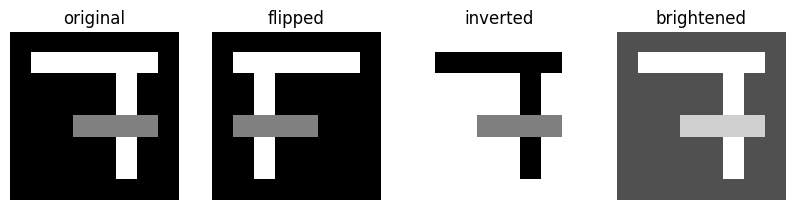

In [22]:
# T10: An image is an array
img = np.zeros((8, 8), dtype=int)                                          # (a)
img[1, 1:7] = 255          # top bar of the 7 (white)
img[2:7, 5] = 255          # diagonal-ish stem (white)
img[4, 3:7] = 128          # grey cross-bar
print("T10a original '7':\n", img)

flipped = img[:, ::-1]                                                     # (b) left-right
print("T10b flipped:\n", flipped)

inverted = 255 - img                                                       # (c)
print("T10c inverted:\n", inverted)

crop = img[1:5, 3:7]                                                       # (d) rows 1-4, cols 3-6
print("T10d crop (rows 1-4, cols 3-6):\n", crop)

bright = np.clip(img + 80, 0, 255)                                         # (e)
print("T10e brightened by 80 (cap 255):\n", bright)

print("T10f shape:", img.shape, "| dtype:", img.dtype, "| white pixels (=255):", (img == 255).sum())  # (f)

# Optional: look at it
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for a, im, t in zip(ax, [img, flipped, inverted, bright], ["original", "flipped", "inverted", "brightened"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()

## Task 11 · Reflection (Markdown cell)
Write 3–5 sentences: one finding from the census, one from the climate data and one from inflation that you did not know before. Then name one NumPy function that saved you from writing a loop, and what the loop would have looked like.

**Census:** AJK grew by only about 1.15 % a year between 2017 and 2023, less than half of Pakistan's overall 2.5 %, while Balochistan grew fastest at 3.19 %. **Climate:** Quetta gets only about 6 % of its yearly rain in the monsoon, because its rain falls in winter and spring. **Inflation:** Pakistan's average year-on-year inflation fell from about 26.2 % in FY2024 to 4.9 % in FY2025, reaching just 0.3 % by April 2025. The function that saved me the most work was `tmax.mean(axis=1)` (and likewise `sum(axis=1)` for the monsoon rain): without it I would have written a `for` loop over the 5 cities, an inner loop over the 12 months to add up the values, a running total, and a division by 12 for each city.